<a href="https://colab.research.google.com/github/abhinavkathoute31-boop/FML-PROJECT/blob/main/FML_Practicals_Football_Matches.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FML Project Football Match Dataset


## Setup and upload the CSV

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
uploaded = files.upload()  # Select finished_matches(1).csv

csv_name = next((name for name in uploaded if name.lower().endswith(".csv")), None)
if csv_name is None:
    raise ValueError("Please upload a CSV file.")
df = pd.read_csv(csv_name)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
display(df.head())

Saving finished_matches.csv to finished_matches (3).csv
Dataset shape: (104, 34)

Columns:
['match_id', 'matchday', 'matchday_name', 'matchday_long_name', 'round_name', 'league_name', 'group_name', 'status', 'kickoff_date', 'kickoff_time', 'home_team_id', 'home_team_name', 'home_team_code', 'away_team_id', 'away_team_name', 'away_team_code', 'home_score', 'away_score', 'home_score_regular', 'away_score_regular', 'result', 'winner_team_name', 'winner_team_id', 'total_goals', 'goal_difference', 'home_points', 'away_points', 'stadium_name', 'stadium_city', 'stadium_country_code', 'match_attendance', 'matchday_format', 'round_mode', 'scraped_at']


,match_id,matchday,matchday_name,matchday_long_name,round_name,league_name,group_name,status,kickoff_date,kickoff_time,...,goal_difference,home_points,away_points,stadium_name,stadium_city,stadium_country_code,match_attendance,matchday_format,round_mode,scraped_at
0,2048009,1,MD1,Matchday 1,League phase,League D,Group D1,FINISHED,2026-09-24,2026-09-24T16:00:00Z,...,-1,0,3,Estadi FAF,Encamp,AND,905.0,REGULAR,GROUP,2026-10-13T02:19:32Z
1,2048002,1,MD1,Matchday 1,League phase,League A,Group A4,FINISHED,2026-09-24,2026-09-24T18:45:00Z,...,1,3,0,Estádio José Alvalade,Lisbon,POR,47725.0,REGULAR,GROUP,2026-10-13T02:19:32Z
2,2048003,1,MD1,Matchday 1,League phase,League A,Group A2,FINISHED,2026-09-24,2026-09-24T18:45:00Z,...,0,1,1,Johan Cruijff ArenA,Amsterdam,NED,51437.0,REGULAR,GROUP,2026-10-13T02:19:32Z
3,2048004,1,MD1,Matchday 1,League phase,League A,Group A2,FINISHED,2026-09-24,2026-09-24T18:45:00Z,...,-1,0,3,Stadion Rajko Mitić,Belgrade,SRB,5701.0,REGULAR,GROUP,2026-10-13T02:19:32Z
4,2048005,1,MD1,Matchday 1,League phase,League A,Group A4,FINISHED,2026-09-24,2026-09-24T18:45:00Z,...,1,3,0,Ullevaal Stadion,Oslo,NOR,25002.0,REGULAR,GROUP,2026-10-13T02:19:32Z


##  Data Preprocessing and Feature Engineering



In [ ]:
# Work on a copy so the original data remains unchanged
data = df.copy()

print("Rows and columns before cleaning:", data.shape)
print("\nMissing values per column:")
display(data.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

duplicates = data.duplicated().sum()
print("Duplicate rows:", duplicates)
data = data.drop_duplicates().copy()

# Convert date fields and derive a numeric month feature when possible
data["kickoff_date"] = pd.to_datetime(data["kickoff_date"], errors="coerce")
data["kickoff_month"] = data["kickoff_date"].dt.month

# Standardize text columns
for col in data.select_dtypes(include="object").columns:
    data[col] = data[col].astype("string").str.strip()

print("Rows and columns after removing duplicates:", data.shape)
display(data[["matchday", "home_team_name", "away_team_name",
              "home_score", "away_score", "result", "total_goals",
              "kickoff_month"]].head())

Rows and columns before cleaning: (104, 34)

Missing values per column:


,missing_count
winner_team_id,28
match_attendance,4
matchday,0
match_id,0
matchday_name,0
matchday_long_name,0
group_name,0
status,0
round_name,0
league_name,0


Duplicate rows: 0
Rows and columns after removing duplicates: (104, 35)


,matchday,home_team_name,away_team_name,home_score,away_score,result,total_goals,kickoff_month
0,1,Andorra,Malta,1,2,AWAY_WIN,3,9
1,1,Portugal,Wales,1,0,HOME_WIN,1,9
2,1,Netherlands,Germany,1,1,DRAW,2,9
3,1,Serbia,Greece,1,2,AWAY_WIN,3,9
4,1,Norway,Denmark,3,2,HOME_WIN,5,9


## Linear Regression for Total Goals Prediction



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

reg_features = ["matchday", "home_team_code", "away_team_code",
                "league_name", "group_name", "round_name"]
reg_target = "total_goals"

reg_data = data.dropna(subset=[reg_target]).copy()
X_reg = reg_data[reg_features]
y_reg = reg_data[reg_target]

reg_num = ["matchday"]
reg_cat = [c for c in reg_features if c not in reg_num]

reg_preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), reg_num),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), reg_cat)
])

X_train, X_test, y_train, y_test = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=42
)
linear_model = Pipeline([
    ("preprocess", reg_preprocessor),
    ("model", LinearRegression())
])
linear_model.fit(X_train, y_train)
pred = linear_model.predict(X_test)

print("Mean Absolute Error:", round(mean_absolute_error(y_test, pred), 3))
print("Root Mean Squared Error:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
print("R² score:", round(r2_score(y_test, pred), 3))
display(pd.DataFrame({"Actual total goals": y_test.values,
                      "Predicted total goals": np.round(pred, 2)}).head(10))

Mean Absolute Error: 2.124
Root Mean Squared Error: 2.775
R² score: -4.185


,Actual total goals,Predicted total goals
0,3,3.17
1,3,4.00
2,2,4.88
3,3,3.83
4,3,7.62
5,1,6.33
6,5,1.75
7,0,1.33
8,2,5.88
9,3,2.76


## Logistic Regression for Match Result Classification



Accuracy: 0.423
              precision    recall  f1-score   support

    AWAY_WIN       0.62      0.56      0.59         9
        DRAW       0.33      0.29      0.31         7
    HOME_WIN       0.33      0.40      0.36        10

    accuracy                           0.42        26
   macro avg       0.43      0.41      0.42        26
weighted avg       0.43      0.42      0.43        26



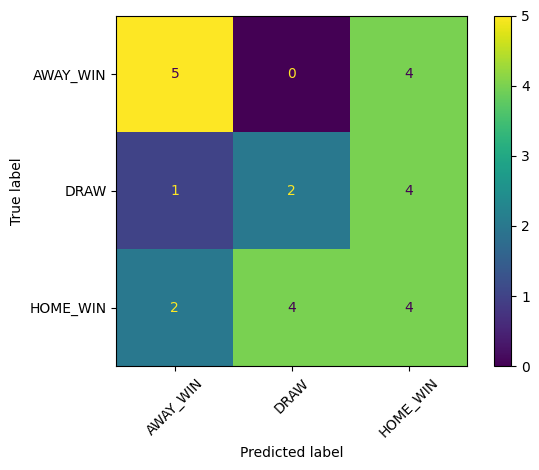

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

class_features = ["matchday", "home_team_code", "away_team_code",
                  "league_name", "group_name", "round_name"]
class_data = data.dropna(subset=["result"]).copy()
X_cls = class_data[class_features]
y_cls = class_data["result"].astype(str)

# Use stratification only when every class has enough examples
stratify_arg = y_cls if y_cls.value_counts().min() >= 2 else None
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cls, y_cls, test_size=0.25, random_state=42, stratify=stratify_arg
)

cls_num = ["matchday"]
cls_cat = [c for c in class_features if c not in cls_num]
cls_preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), cls_num),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cls_cat)
])

logistic_model = Pipeline([
    ("preprocess", cls_preprocessor),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))
])
logistic_model.fit(X_train_c, y_train_c)
pred_c = logistic_model.predict(X_test_c)

print("Accuracy:", round(accuracy_score(y_test_c, pred_c), 3))
print(classification_report(y_test_c, pred_c, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test_c, pred_c, xticks_rotation=45)
plt.tight_layout()
plt.show()

##  Decision Tree Classification



Decision Tree accuracy: 0.385
              precision    recall  f1-score   support

    AWAY_WIN       0.00      0.00      0.00         9
        DRAW       0.00      0.00      0.00         7
    HOME_WIN       0.38      1.00      0.56        10

    accuracy                           0.38        26
   macro avg       0.13      0.33      0.19        26
weighted avg       0.15      0.38      0.21        26



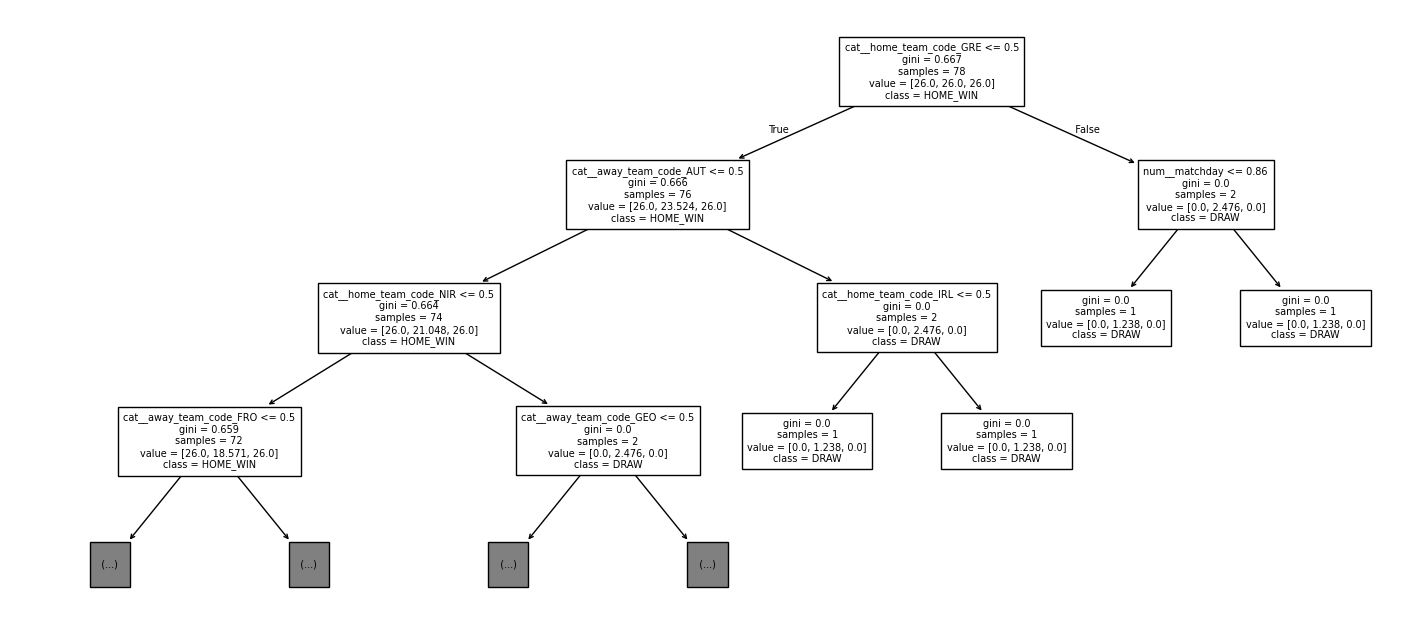

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree_model = Pipeline([
    ("preprocess", cls_preprocessor),
    ("model", DecisionTreeClassifier(max_depth=4, random_state=42,
                                     class_weight="balanced"))
])
tree_model.fit(X_train_c, y_train_c)
tree_pred = tree_model.predict(X_test_c)

print("Decision Tree accuracy:", round(accuracy_score(y_test_c, tree_pred), 3))
print(classification_report(y_test_c, tree_pred, zero_division=0))

# Plot a readable tree (after preprocessing)
feature_names = tree_model.named_steps["preprocess"].get_feature_names_out()
plt.figure(figsize=(18, 8))
plot_tree(tree_model.named_steps["model"], feature_names=feature_names,
          class_names=tree_model.named_steps["model"].classes_,
          filled=False, max_depth=3, fontsize=7)
plt.show()

##  Random Forest Classification



Random Forest accuracy: 0.346
              precision    recall  f1-score   support

    AWAY_WIN       0.42      0.56      0.48         9
        DRAW       0.00      0.00      0.00         7
    HOME_WIN       0.33      0.40      0.36        10

    accuracy                           0.35        26
   macro avg       0.25      0.32      0.28        26
weighted avg       0.27      0.35      0.30        26



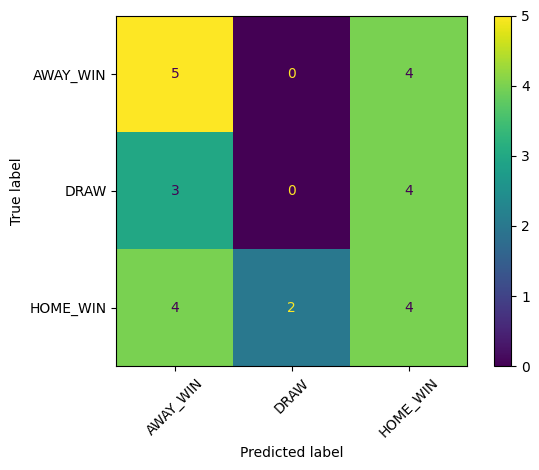

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocess", cls_preprocessor),
    ("model", RandomForestClassifier(n_estimators=200, max_depth=5,
                                     random_state=42, class_weight="balanced"))
])
rf_model.fit(X_train_c, y_train_c)
rf_pred = rf_model.predict(X_test_c)

print("Random Forest accuracy:", round(accuracy_score(y_test_c, rf_pred), 3))
print(classification_report(y_test_c, rf_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test_c, rf_pred, xticks_rotation=45)
plt.tight_layout()
plt.show()

## Support Vector Machine (SVM)



In [ ]:
from sklearn.svm import SVC

svm_model = Pipeline([
    ("preprocess", cls_preprocessor),
    ("model", SVC(kernel="rbf", class_weight="balanced"))
])
svm_model.fit(X_train_c, y_train_c)
svm_pred = svm_model.predict(X_test_c)

print("SVM accuracy:", round(accuracy_score(y_test_c, svm_pred), 3))
print(classification_report(y_test_c, svm_pred, zero_division=0))

SVM accuracy: 0.423
              precision    recall  f1-score   support

    AWAY_WIN       0.56      0.56      0.56         9
        DRAW       0.33      0.29      0.31         7
    HOME_WIN       0.36      0.40      0.38        10

    accuracy                           0.42        26
   macro avg       0.42      0.41      0.41        26
weighted avg       0.42      0.42      0.42        26



##  K-Means Clustering



In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = ["home_score", "away_score", "total_goals",
                    "goal_difference", "match_attendance"]
cluster_data = data[cluster_features].copy()

cluster_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
X_cluster = cluster_pipe.fit_transform(cluster_data)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_cluster)
data["kmeans_cluster"] = cluster_labels

print("Cluster counts:")
display(data["kmeans_cluster"].value_counts().sort_index().to_frame("matches"))
if len(set(cluster_labels)) > 1:
    print("Silhouette score:", round(silhouette_score(X_cluster, cluster_labels), 3))

display(data[["home_team_name", "away_team_name", "home_score",
              "away_score", "total_goals", "kmeans_cluster"]].head(12))

Cluster counts:


,matches
kmeans_cluster,
0,35
1,39
2,30


Silhouette score: 0.328


,home_team_name,away_team_name,home_score,away_score,total_goals,kmeans_cluster
0,Andorra,Malta,1,2,3,2
1,Portugal,Wales,1,0,1,1
2,Netherlands,Germany,1,1,2,1
3,Serbia,Greece,1,2,3,2
4,Norway,Denmark,3,2,5,0
5,Austria,Israel,3,1,4,0
6,Kosovo,Republic of Ireland,1,0,1,1
7,Liechtenstein,Lithuania,0,2,2,2
8,Georgia,Northern Ireland,0,1,1,1
9,Armenia,Latvia,2,0,2,0


## P Hierarchical Clustering



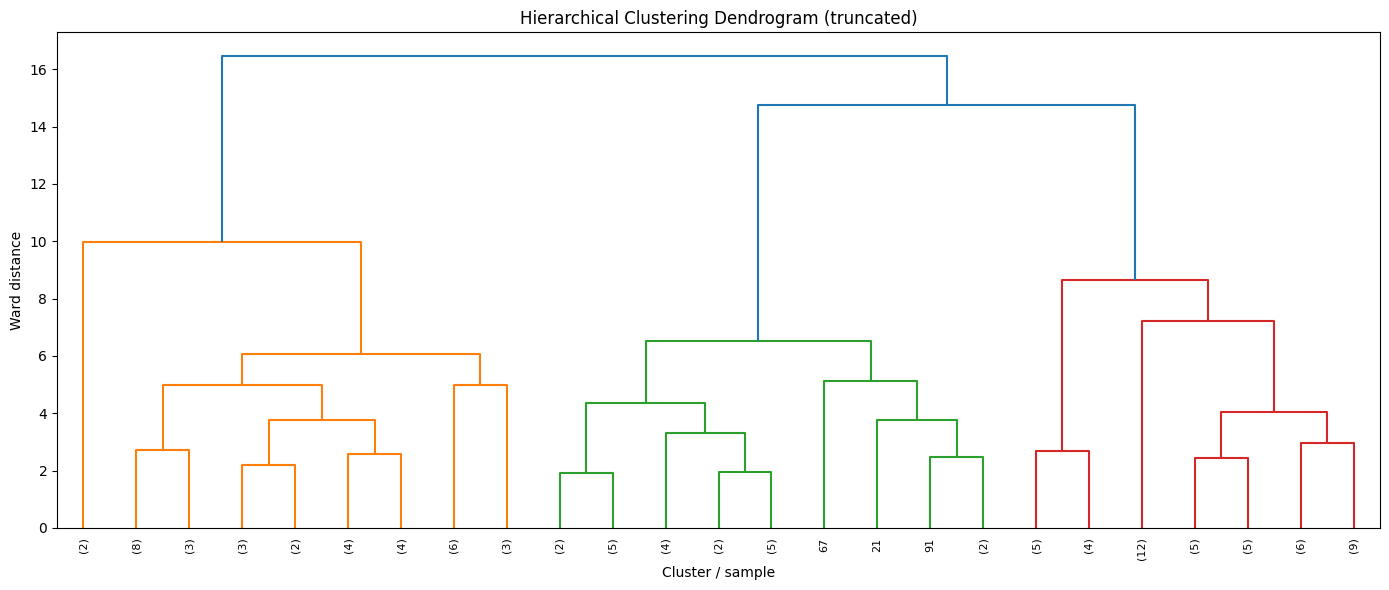

,home_team_name,away_team_name,total_goals,hierarchical_cluster
0,Andorra,Malta,3,0
1,Portugal,Wales,1,1
2,Netherlands,Germany,2,1
3,Serbia,Greece,3,0
4,Norway,Denmark,5,2
5,Austria,Israel,4,2
6,Kosovo,Republic of Ireland,1,1
7,Liechtenstein,Lithuania,2,0
8,Georgia,Northern Ireland,1,0
9,Armenia,Latvia,2,1


In [ ]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Ensure X_cluster is defined even if the previous cell wasn't run
if 'X_cluster' not in globals():
    cluster_features = ["home_score", "away_score", "total_goals",
                        "goal_difference", "match_attendance"]
    cluster_data = data[cluster_features].copy()
    cluster_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    X_cluster = cluster_pipe.fit_transform(cluster_data)

# Standardized numerical features
Z = linkage(X_cluster, method="ward")
plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=25, leaf_rotation=90, leaf_font_size=8)
plt.title("Hierarchical Clustering Dendrogram (truncated)")
plt.xlabel("Cluster / sample")
plt.ylabel("Ward distance")
plt.tight_layout()
plt.show()

hier = AgglomerativeClustering(n_clusters=3, linkage="ward")
data["hierarchical_cluster"] = hier.fit_predict(X_cluster)
display(data[["home_team_name", "away_team_name", "total_goals",
              "hierarchical_cluster"]].head(12))

## Single-Layer Perceptron



In [ ]:
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, classification_report

perc_data = class_data.copy()
perc_data["home_win_binary"] = (perc_data["result"] == "HOME_WIN").astype(int)
X_p = perc_data[class_features]
y_p = perc_data["home_win_binary"]

stratify_p = y_p if y_p.value_counts().min() >= 2 else None
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_p, y_p, test_size=0.25, random_state=42, stratify=stratify_p
)

perc_preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), ["matchday"]),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]),
     [c for c in class_features if c != "matchday"])
])

perceptron_model = Pipeline([
    ("preprocess", perc_preprocessor),
    ("model", Perceptron(max_iter=2000, random_state=42,
                         class_weight="balanced"))
])
perceptron_model.fit(X_train_p, y_train_p)
pred_p = perceptron_model.predict(X_test_p)

print("Perceptron accuracy:", round(accuracy_score(y_test_p, pred_p), 3))
print(classification_report(y_test_p, pred_p, zero_division=0))

Perceptron accuracy: 0.615
              precision    recall  f1-score   support

           0       0.75      0.56      0.64        16
           1       0.50      0.70      0.58        10

    accuracy                           0.62        26
   macro avg       0.62      0.63      0.61        26
weighted avg       0.65      0.62      0.62        26



##  Artificial Neural Network (Forward and Backward Propagation)



In [ ]:
from sklearn.neural_network import MLPClassifier

ann_model = Pipeline([
    ("preprocess", perc_preprocessor),
    ("model", MLPClassifier(hidden_layer_sizes=(8,), activation="relu",
                            solver="adam", max_iter=1500, random_state=42,
                            early_stopping=False))
])
ann_model.fit(X_train_p, y_train_p)
ann_pred = ann_model.predict(X_test_p)

print("ANN accuracy:", round(accuracy_score(y_test_p, ann_pred), 3))
print(classification_report(y_test_p, ann_pred, zero_division=0))

ANN accuracy: 0.692
              precision    recall  f1-score   support

           0       0.72      0.81      0.76        16
           1       0.62      0.50      0.56        10

    accuracy                           0.69        26
   macro avg       0.67      0.66      0.66        26
weighted avg       0.68      0.69      0.68        26



### Manual forward propagation and one backpropagation update

In [ ]:
# Educational example: one hidden neuron and one output neuron.
# Inputs come from the first match's home/away scores; label is whether it was a home win.
# This is a single illustrative gradient update, not a complete trained model.

row = data.iloc[0]
x = np.array([row["home_score"], row["away_score"]], dtype=float)
x = x / max(1.0, np.max(np.abs(x)))  # simple scaling
y_true = float(row["result"] == "HOME_WIN")

# Fixed initial weights/biases for reproducibility
W1 = np.array([[0.2, -0.1],
               [0.1,  0.3]])  # 2 inputs -> 2 hidden units
b1 = np.array([0.0, 0.0])
W2 = np.array([[0.4], [-0.2]])  # 2 hidden units -> 1 output
b2 = np.array([0.0])

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))

# Forward pass
z1 = x @ W1 + b1
a1 = np.maximum(0, z1)  # ReLU hidden layer
z2 = a1 @ W2 + b2
y_pred = sigmoid(z2)[0]
loss = 0.5 * (y_pred - y_true) ** 2

# Backward pass for squared-error loss
delta2 = (y_pred - y_true) * y_pred * (1 - y_pred)
grad_W2 = np.outer(a1, [delta2])
grad_b2 = np.array([delta2])
delta1 = (W2[:, 0] * delta2) * (z1 > 0)
grad_W1 = np.outer(x, delta1)
grad_b1 = delta1

learning_rate = 0.1
W2 -= learning_rate * grad_W2
b2 -= learning_rate * grad_b2
W1 -= learning_rate * grad_W1
b1 -= learning_rate * grad_b1

print("Input (scaled home/away scores):", x)
print("Actual label (home win=1, otherwise=0):", y_true)
print("Prediction before update:", round(float(y_pred), 4))
print("Loss before update:", round(float(loss), 6))
print("Updated W1:\n", W1)
print("Updated W2:\n", W2)

Input (scaled home/away scores): [0.5 1. ]
Actual label (home win=1, otherwise=0): 0.0
Prediction before update: 0.5075
Loss before update: 0.128778
Updated W1:
 [[ 0.19746307 -0.09873154]
 [ 0.09492615  0.30253693]]
Updated W2:
 [[ 0.39746307]
 [-0.20317116]]


## Final comparison of model performance

This summary compares the test-set accuracy of the classification models. Since the dataset is small, do not treat a single split as a reliable estimate of future performance.

In [ ]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest", "SVM",
              "Single-Layer Perceptron", "ANN (MLP)"],
    "Accuracy": [
        accuracy_score(y_test_c, pred_c),
        accuracy_score(y_test_c, tree_pred),
        accuracy_score(y_test_c, rf_pred),
        accuracy_score(y_test_c, svm_pred),
        accuracy_score(y_test_p, pred_p),
        accuracy_score(y_test_p, ann_pred)
    ],
    "Task": ["3-class result", "3-class result", "3-class result", "3-class result",
             "Home win vs other", "Home win vs other"]
})
display(comparison)
print("Notebook complete: all 10 practical sections have been run.")

,Model,Accuracy,Task
0,Logistic Regression,0.423077,3-class result
1,Decision Tree,0.384615,3-class result
2,Random Forest,0.346154,3-class result
3,SVM,0.423077,3-class result
4,Single-Layer Perceptron,0.615385,Home win vs other
5,ANN (MLP),0.692308,Home win vs other


Notebook complete: all 10 practical sections have been run.
